# Propane parameter estimation


**Evidence: calibration.** Fit three PC-SAFT pure-fluid parameters to six
observations, saturation pressure and saturated liquid mass density at
210, 270 and 330 K. Start from `gross-2001-propane/3`, Gross and Sadowski (2001),
Table 2 ([paper](https://doi.org/10.1021/ie0003887)).

The observations are Glos, Kleinrahm and Wagner (2004), Table 2
([paper](https://doi.org/10.1016/j.jct.2004.07.017)), retained as
`analyses/2026-pure-saturation-regression/inputs/source/propane-baseline.csv`.
Zotero `NF5HJCV7` is metadata only; no local PDF attachment is claimed.
The [official NIST/TRC ThermoML record](https://trc.nist.gov/ThermoML/10.1016/j.jct.2004.07.017.html)
provides the machine-readable measurements. The retained source record
`analyses/reproduction/2004-glos/inputs/source/glos-2004-propane-saturation.yaml`
documents the compact factual extraction and source-specific use basis.
Source pressures in kPa were multiplied by exactly 1000 to obtain the Pa
values read from the teaching CSV; mass densities remain in kg/m³.


## Read the inputs

Use a repository checkout with the environment described in the installation
guide. The wheel alone does not contain these data. All density, association,
equilibrium and parameter-fit iterations below run in the native Engine.


In [1]:
from pathlib import Path
import csv
import pandas as pd
from IPython.display import display
from epcsaft import (
    Parameters,
    Pure,
)
from epcsaft import equilibrium as eq, regression as rg

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

ROOT = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "ARCHITECTURE.yaml").is_file()
)
PACKETS = ROOT / "data" / "packets"


## Declare observations, coordinates and one native fit

Each observation uses a zero-vapor-amount saturation declaration. Log-ratio
residuals have unit weight, a calibration choice rather than source measurement
uncertainty. Coordinates use origin/scale/bounds:

| Parameter | Origin | Scale | Bounds |
|---|---:|---:|---:|
| Dispersion energy/k / K | 221 | 10 | 150–260 |
| Segment count / 1 | 1.9489 | 0.1 | 1.5–2.5 |
| Segment diameter / Å | 3.7209 | 0.1 | 3–4.2 |

The native budget is 100 iterations and 60 s, with one published-packet start.
Require usable parameters, lower cost, and independent native re-evaluation
of all fitted predictions within 10⁻¹⁰ relative.


In [2]:
start = Parameters.from_json(
    PACKETS / "gross-2001-propane/3/parameters/parameters.json", components=["propane"]
)
rows = list(
    csv.DictReader(
        (
            ROOT
            / "analyses/2026-pure-saturation-regression/inputs/source/propane-baseline.csv"
        ).open()
    )
)
observations = []
for row in rows:
    problem = eq.Problem(
        T=float(row["temperature_k"]),
        P=eq.Free(float(row["saturation_pressure"])),
        feed=eq.Amounts({"propane": 1}),
        phases=[
            eq.Phase("L", kind="liquid"),
            eq.Phase("V", kind="vapor", amount=eq.Pinned(0)),
        ],
        row_tolerance=1e-10,
    )
    observations += [
        rg.observation(
            start,
            "pressure",
            problem,
            observed=float(row["saturation_pressure"]),
            form="log_ratio",
        ),
        rg.observation(
            start,
            "phase_density",
            problem,
            observed=float(row["saturated_liquid_mass_density"]),
            phase="L",
            form="log_ratio",
            mass_basis=True,
        ),
    ]
coordinates = [
    rg.coordinate(
        start, [(name, "propane", 1)], origin=origin, scale=scale, bounds=bounds
    )
    for name, origin, scale, bounds in [
        ("dispersion_energy_over_k", 221, 10, (150, 260)),
        ("segment_count", 1.9489, 0.1, (1.5, 2.5)),
        ("segment_diameter", 3.7209, 0.1, (3, 4.2)),
    ]
]
fit_result = rg.fit(
    start,
    coordinates,
    observations,
    controls=rg.FitControls(maximum_iterations=100, maximum_elapsed_time_seconds=60),
)
assert fit_result.usable, fit_result.message
assert fit_result.final_cost < fit_result.initial_cost
fitted_parameters = rg.fitted_parameters(start, fit_result)
predictions = [
    rg.predict(Pure(fitted_parameters), observation).value
    for observation in observations
]
assert all(
    (
        abs(a - b) < 1e-10 * max(abs(a), 1)
        for a, b in zip(predictions, fit_result.predictions)
    )
)
values = dict(
    physical=fit_result.physical,
    initial_cost=fit_result.initial_cost,
    final_cost=fit_result.final_cost,
    iterations=fit_result.iterations,
    predictions=fit_result.predictions,
    residuals=fit_result.residuals,
    covariance_rank=fit_result.covariance.rank,
    covariance_assumption=fit_result.covariance.assumption,
    observed=[o.observed for o in observations],
)
values["prediction_round_trip_relative_error"] = max(
    (abs(a - b) / abs(a) for a, b in zip(predictions, fit_result.predictions))
)
assert values["prediction_round_trip_relative_error"] <= 1e-10
display(
    pd.DataFrame(
        {
            "Observation": ["Pressure / Pa", "Liquid density / kg m^-3"] * 3,
            "Temperature / K": [210, 210, 270, 270, 330, 330],
            "Observed": values["observed"],
            "Fitted prediction": values["predictions"],
            "Log-ratio residual / 1": values["residuals"],
        }
    )
)


,Observation,Temperature / K,Observed,Fitted prediction,Log-ratio residual / 1
0,Pressure / Pa,210,36032.000,3.602740e+04,-0.000128
1,Liquid density / kg m^-3,210,604.594,6.033307e+02,-0.002092
2,Pressure / Pa,270,430425.000,4.305303e+05,0.000245
3,Liquid density / kg m^-3,270,532.853,5.337605e+02,0.001702
4,Pressure / Pa,330,1983000.000,1.983084e+06,0.000042
5,Liquid density / kg m^-3,330,434.869,4.349694e+02,0.000231


## Inspect calibration residuals

Rows alternate saturation pressure and liquid density at the three temperatures.
These are residuals against the same measurements used in the fit.


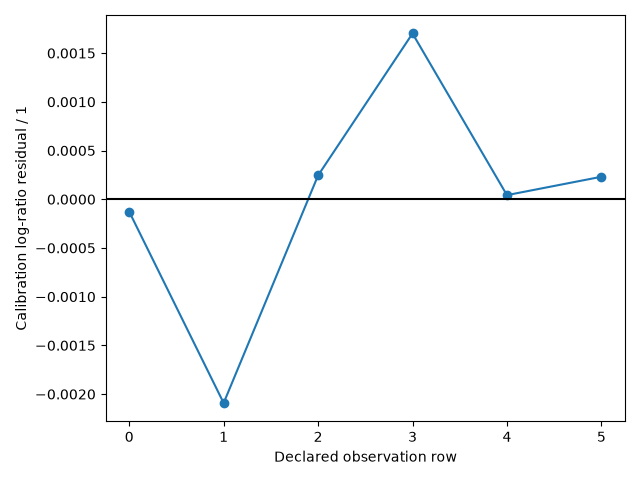

In [3]:
from io import BytesIO
from IPython.display import Image
import matplotlib.pyplot as plt

plt.plot(range(6), values["residuals"], marker="o")
plt.axhline(0, color="black")
plt.xlabel("Declared observation row")
plt.ylabel("Calibration log-ratio residual / 1")
buffer = BytesIO()
plt.tight_layout()
plt.savefig(buffer, format="png")
plt.close()
display(Image(data=buffer.getvalue()))


In [4]:
display(pd.DataFrame({
    "Dispersion energy/k / K": [values["physical"][0]],
    "Segment count / 1": [values["physical"][1]],
    "Segment diameter / Å": [values["physical"][2]],
}))
display(pd.DataFrame([{
    "Initial cost / 1": values["initial_cost"],
    "Final cost / 1": values["final_cost"],
    "Iterations / 1": values["iterations"],
    "Covariance rank / 1": values["covariance_rank"],
    "Covariance assumption": values["covariance_assumption"],
    "Prediction round-trip relative error / 1": values["prediction_round_trip_relative_error"],
}]))


,Dispersion energy/k / K,Segment count / 1,Segment diameter / Å
0,208.511249,1.996456,3.619429


,Initial cost / 1,Final cost / 1,Iterations / 1,Covariance rank / 1,Covariance assumption,Prediction round-trip relative error / 1
0,0.000014,0.000004,4,3,"unit-variance weighted residuals, independent errors and a regular local linearization at an interior point; multiply by variance_factor for an unknown common variance; no claim under bounds, rank deficiency or model discrepancy",3.029344e-15


## Meaning and limits


This is calibration against direct measurements. It supplies no independent
validation set or new predictive accuracy floor. The printed covariance rank
and assumption describe a local linearized calculation conditional on the
declared weights and residual model. They do not establish global
identifiability or predictive uncertainty. The fitted values are a tutorial
result, not a newly adopted canonical parameter set.
